# GLP-1 Utilization & Health Needs Across U.S. States
**IS 507 · Group 1 — Midterm EDA**

**Purpose:** This notebook conducts exploratory data analysis (EDA) of three datasets (**Medicaid Drug Utilization, CDC BRFSS, and Medicaid Enrollment**) to assess data quality, identify potential challenges, and prepare for analyzing state-level Medicaid GLP-1 prescription rates in relation to obesity and diabetes prevalence during 2025.

## 1. Setup
### 1.1 Import packages

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


### 1.2 Set input file paths

In [2]:
# Set paths to the three datasets used in the project report.
SDUD_PATH = Path('sdud2025_updatedjuly2026.csv')
BRFSS_PATH = Path('LLCP2025.XPT_')
ENROLLMENT_PATH = Path('pi-dataset-september-2026-release.csv')

# Number of SDUD rows read per chunk.
CHUNK_SIZE = 150_000


### 1.3 File checks and data loading

In [3]:
# Check whether the specified file exists.
def require_file(path):
    if not path.exists():
        raise FileNotFoundError(f'File not found: {path.resolve()} — update its path in the configuration cell.')

# Load a dataset using the appropriate reader based on its file format.
def read_tabular(path, **kwargs):
    require_file(path)
    suffix = path.suffix.lower()
    if suffix == '.csv': return pd.read_csv(path, low_memory=False, **kwargs)
    if suffix in ('.parquet', '.pq'): return pd.read_parquet(path, **kwargs)
    if suffix in ('.xpt', '.xpt_'): return pd.read_sas(path, format='xport', **kwargs)
    if suffix in ('.xlsx', '.xls'): return pd.read_excel(path, **kwargs)
    raise ValueError(f'Unsupported file format: {suffix}')


## 2. [CMS State Drug Utilization (SDUD)](https://data.medicaid.gov/dataset/158a1baa-5506-400a-8ec3-97756f0b0536#data-dictionary)

**Goal:** Identify candidate GLP-1 products, examine observed prescription counts by state and quarter, and assess data suppression. **Suppressed prescription counts must not be treated as zero.**

### 2.1 Select report key variables
Only the seven report columns are selected. The full SDUD file is not loaded into memory.

In [4]:
# Verify the input file and select exactly the seven report variables.
require_file(SDUD_PATH)
if SDUD_PATH.suffix.lower() != '.csv':
    raise ValueError('The SDUD file must be a CSV.')
S = {
    'state': 'State',
    'ndc': 'NDC',
    'year': 'Year',
    'quarter': 'Quarter',
    'product': 'Product Name',
    'prescriptions': 'Number of Prescriptions',
    'suppressed': 'Suppression Used',
}
sdud_headers = pd.read_csv(SDUD_PATH, nrows=0).columns.tolist()
missing = [name for name in S.values() if name not in sdud_headers]
if missing:
    raise KeyError(f'Missing SDUD report columns: {missing}')
print('Selected SDUD columns:', list(S.values()))
# Inspect source-file dtypes before NDC is preserved as a string for filtering.
sdud_dtype_sample = pd.read_csv(SDUD_PATH, usecols=list(S.values()), nrows=10000, low_memory=False)
print('SDUD key variable source dtypes (10,000-row sample):', sdud_dtype_sample.dtypes.astype(str).to_dict())


Selected SDUD columns: ['State', 'NDC', 'Year', 'Quarter', 'Product Name', 'Number of Prescriptions', 'Suppression Used']
SDUD key variable source dtypes (10,000-row sample): {'State': 'str', 'NDC': 'int64', 'Year': 'int64', 'Quarter': 'int64', 'Suppression Used': 'bool', 'Product Name': 'str', 'Number of Prescriptions': 'float64'}


### 2.2 Define a preliminary GLP-1 brand list
This is a screening list, not a validated NDC classification. Verify product names and NDCs against official sources before final analysis.

In [5]:
# Define GLP-1 product names based on FDA Product Name List
GLP1_BRANDS = [
    'BYETTA', 'VICTOZA', 'TRULICITY', 'SAXENDA',
    'ADLYXIN', 'XULTOPHY', 'SOLIQUA', 'BYDUREON',
    'OZEMPIC', 'RYBELSUS', 'WEGOVY', 'MOUNJARO', 'ZEPBOUND'
]

# Create a regex pattern to identify GLP-1 products.
pattern = r'\b(?:' + '|'.join(map(re.escape, GLP1_BRANDS)) + r')\b'

In [6]:
# Filter 2025 GLP-1 candidates while reading only seven columns in chunks.
glp1_chunks = []
raw_rows = 0
rows_2025 = 0
for chunk in pd.read_csv(
    SDUD_PATH, usecols=list(S.values()), chunksize=CHUNK_SIZE,
    dtype={S['ndc']: 'string'}, low_memory=False
):
    raw_rows += len(chunk)
    is_2025 = pd.to_numeric(chunk[S['year']], errors='coerce').eq(2025)
    rows_2025 += int(is_2025.sum())
    is_glp1 = chunk[S['product']].astype('string').str.contains(
        pattern, case=False, na=False, regex=True
    )
    filtered = chunk.loc[is_2025 & is_glp1].copy()
    if not filtered.empty:
        glp1_chunks.append(filtered)

# Combine only the candidate records, not the full SDUD dataset.
glp1 = (pd.concat(glp1_chunks, ignore_index=True) if glp1_chunks
        else pd.DataFrame(columns=list(S.values())))
print(f'All SDUD rows: {raw_rows:,}')
print(f'2025 SDUD rows: {rows_2025:,}')
print(f'2025 candidate GLP-1 rows: {len(glp1):,}')
display(glp1.head())
print(f'SDUD full dataset shape: ({raw_rows:,}, {len(sdud_headers)})')
print('SDUD working dtypes (NDC preserved as string):', glp1[list(S.values())].dtypes.astype(str).to_dict())

All SDUD rows: 5,308,547
2025 SDUD rows: 5,308,547
2025 candidate GLP-1 rows: 11,060


,State,NDC,Year,Quarter,Suppression Used,Product Name,Number of Prescriptions
0,AK,00002143380,2025,4,False,TRULICITY,113.0
1,AK,00002143380,2025,4,True,TRULICITY,NaN
2,AK,00002143480,2025,4,False,TRULICITY,147.0
3,AK,00002143480,2025,4,True,TRULICITY,NaN
4,AK,00002145780,2025,4,False,MOUNJARO,95.0


SDUD full dataset shape: (5,308,547, 15)
SDUD working dtypes (NDC preserved as string): {'State': 'str', 'NDC': 'string', 'Year': 'int64', 'Quarter': 'int64', 'Product Name': 'str', 'Number of Prescriptions': 'float64', 'Suppression Used': 'bool'}


**Interpretation:** The file contains **5,308,547 records**, all labeled 2025. And **11,060 records** match the preliminary GLP-1 brand-name filter using **FDA GLP-1 Product Name List**. The displayed rows are a preview of the extracted records, not aggregated prescription totals.

* FDA GLP-1 Product Name List: https://www.fda.gov/drugs/drug-safety-communications/update-fdas-ongoing-evaluation-reports-suicidal-thoughts-or-actions-patients-taking-certain-type 

### 2.3 Suppression Used
Inspect suppression status and missing, zero, or positive prescription values among the extracted 2025 GLP-1 candidates. Row shares are not shares of prescriptions.

#### 2.3.1 Prepare suppression status

In [7]:
# Inspect suppression flags among the extracted 2025 GLP-1 candidates.
# This diagnostic does not alter the original data or aggregation.
suppression_flags = glp1[S['suppressed']].astype('string').str.strip().str.lower()
suppression_status = suppression_flags.map({
    'true': 'Suppressed', '1': 'Suppressed', '1.0': 'Suppressed',
    'yes': 'Suppressed', 'y': 'Suppressed',
    'false': 'Not suppressed', '0': 'Not suppressed', '0.0': 'Not suppressed',
    'no': 'Not suppressed', 'n': 'Not suppressed',
}).fillna('Unknown / missing')

suppression_rx = pd.to_numeric(glp1[S['prescriptions']], errors='coerce')
suppression_check = pd.DataFrame({
    'status': suppression_status,
    'rx_missing': suppression_rx.isna(),
    'rx_zero': suppression_rx.eq(0),
    'rx_positive': suppression_rx.gt(0),
    'rx_negative': suppression_rx.lt(0),
})

display(suppression_check.head())

,status,rx_missing,rx_zero,rx_positive,rx_negative
0,Not suppressed,False,False,True,False
1,Suppressed,True,False,False,False
2,Not suppressed,False,False,True,False
3,Suppressed,True,False,False,False
4,Not suppressed,False,False,True,False


**Column definitions:** `status` indicates whether each GLP-1 candidate record is suppressed, not suppressed, or has an unknown suppression status. `rx_missing`, `rx_zero`, `rx_positive`, and `rx_negative` are Boolean indicators showing whether the prescription value is missing or nonnumeric, zero, positive, or negative, respectively.

**Interpretation:** The first five GLP-1 candidate records are shown with their suppression status and prescription-value checks. `True` indicates that a prescription value meets the corresponding condition: missing, zero, positive, or negative. This preview does not represent the distribution of the full dataset. Suppressed counts remain unknown and must not be interpreted as zero.

#### 2.3.2 Display original suppression values

In [8]:
print('Original Suppression Used values (GLP-1 candidates only):')
display(glp1[S['suppressed']].value_counts(dropna=False).to_frame('rows'))


Original Suppression Used values (GLP-1 candidates only):


,rows
Suppression Used,
False,7776
True,3284


**Interpretation:** Among 11,060 GLP-1 candidate records, 7,776 (70.3%) are not suppressed, while 3,284 (29.7%) are suppressed. This indicates that approximately 30% of candidate records have suppression flags, which may affect the completeness of prescription counts. Suppressed prescription values should not be treated as zero.

#### 2.3.3 Summarize prescription values by suppression status

In [9]:
suppression_summary = suppression_check.groupby('status').agg(
    rows=('status', 'size'),
    missing_rx_rows=('rx_missing', 'sum'),
    zero_rx_rows=('rx_zero', 'sum'),
    positive_rx_rows=('rx_positive', 'sum'),
    negative_rx_rows=('rx_negative', 'sum'),
)
suppression_summary['share_of_candidate_rows'] = suppression_summary['rows'] / len(glp1) if len(glp1) else float('nan')
display(suppression_summary)


,rows,missing_rx_rows,zero_rx_rows,positive_rx_rows,negative_rx_rows,share_of_candidate_rows
status,,,,,,
Not suppressed,7776,0,0,7776,0,0.703074
Suppressed,3284,3284,0,0,0,0.296926


**Column definitions:** `rows` counts records in each suppression category. `missing_rx_rows`, `zero_rx_rows`, `positive_rx_rows`, and `negative_rx_rows` count records with missing or nonnumeric, zero, positive, and negative prescription values, respectively. `share_of_candidate_rows` represents each category's proportion of all GLP-1 candidate records, not its share of total prescriptions.

**Interpretation:** All 7,776 non-suppressed records (70.3%) have positive prescription counts, while all 3,284 suppressed records (29.7%) have missing or nonnumeric prescription values. No zero or negative prescription values were found. This confirms that suppression is consistently associated with unavailable prescription counts in the extracted GLP-1 candidate records. Excluding suppressed records may lead to underestimation of GLP-1 utilization.

#### 2.3.4 Check for values requiring review

In [10]:
if suppression_status.eq('Unknown / missing').any():
    print('Review unknown flags before using the existing aggregation: it classifies unrecognized flags as False.')
if (suppression_status.eq('Suppressed') & suppression_rx.notna()).any():
    print('Some suppressed records contain numeric values. These values must not be assumed to be observed prescription counts.')
print('Suppressed counts are unknown, not zero. This table does not estimate hidden prescriptions.')


Suppressed counts are unknown, not zero. This table does not estimate hidden prescriptions.


**Interpretation:** No unrecognized suppression flags or numeric prescription values in suppressed records were detected. Suppressed prescription counts remain unknown and are not treated as zero.

### 2.4 Summarize candidate records and suppression
These are **observed** counts only; suppressed records must never be interpreted as zero.

In [11]:
# Standardize candidate records and separate suppressed prescription counts.
g = glp1.copy()
g['state_clean'] = g[S['state']].astype('string').str.strip().str.upper()
g['quarter_clean'] = pd.to_numeric(g[S['quarter']], errors='coerce')
g['rx'] = pd.to_numeric(g[S['prescriptions']], errors='coerce')
if suppression_status.eq('Unknown / missing').any():
    raise ValueError("Resolve unknown suppression flags before aggregation.")
g['suppressed'] = suppression_status.eq('Suppressed')
g['observed_rx'] = g['rx'].where(~g['suppressed'])

# Aggregate observed prescriptions and suppression by state and quarter.
rx_state_quarter = g.groupby(['state_clean', 'quarter_clean'], dropna=False).agg(
    candidate_rows=('rx', 'size'),
    suppressed_rows=('suppressed', 'sum'),
    observed_rx=('observed_rx', lambda x: x.sum(min_count=1)),
).reset_index().rename(columns={'state_clean': 'state', 'quarter_clean': 'quarter'})
rx_state_quarter['suppressed_share'] = (
    rx_state_quarter['suppressed_rows'] / rx_state_quarter['candidate_rows']
)
display(rx_state_quarter.head(12))


,state,quarter,candidate_rows,suppressed_rows,observed_rx,suppressed_share
0,AK,1,32,11,5695.0,0.343750
1,AK,2,31,10,5770.0,0.322581
2,AK,3,50,28,3989.0,0.560000
3,AK,4,52,29,7436.0,0.557692
4,AL,1,37,16,18188.0,0.432432
5,AL,2,37,13,17968.0,0.351351
6,AL,3,37,11,16651.0,0.297297
7,AL,4,36,6,18304.0,0.166667
8,AR,1,53,22,3532.0,0.415094
9,AR,2,55,23,2700.0,0.418182


**Interpretation:** `candidate_rows` counts GLP-1-matched records, `suppressed_rows` counts flagged records, `observed_rx` sums available prescription counts, and `suppressed_share` is the fraction of rows suppressed. Suppressed prescriptions are **unknown, not zero**.

### 2.5 Plot observed prescriptions by quarter
The chart shows observed counts, not rates or complete totals.

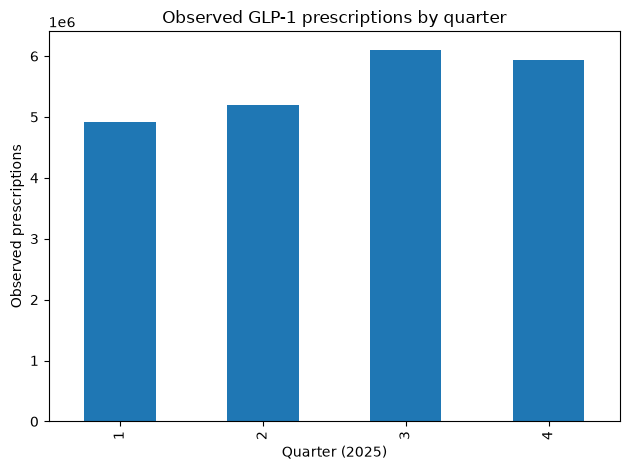

In [12]:
# Visualize quarterly observed prescription counts.
quarter_rx = (
    rx_state_quarter.groupby('quarter')['observed_rx']
    .sum(min_count=1)
    .sort_index()
)
ax = quarter_rx.plot(kind='bar', title='Observed GLP-1 prescriptions by quarter')
ax.set_xlabel('Quarter (2025)')
ax.set_ylabel('Observed prescriptions')
plt.tight_layout()
plt.show()

**Interpretation:** Observed GLP-1 prescriptions rise from approximately **4.9 million in Q1** to **6.1 million in Q3**, then decline slightly to approximately **5.9 million in Q4**. These are combined observed counts across states, not per-enrollee rates or complete totals including suppressed records.


## 3. [CDC BRFSS 2025](https://www.cdc.gov/brfss/annual_data/annual_2025.html)

**Goal:** Explore health and insurance variables, estimate survey-weighted state-level obesity and diabetes prevalence, and assess the feasibility of Medicaid-specific estimates using Medicaid respondent sample sizes. Verify variable categories using the official 2025 BRFSS codebook.

### 3.1 Load and select BRFSS key variables

In [13]:
# Load BRFSS and retain only the five variables listed in the report.
require_file(BRFSS_PATH)
B = {name: name for name in ['_STATE', '_BMI5CAT', 'DIABETE4', '_LLCPWT', 'PRIMINS2']}
brfss = read_tabular(BRFSS_PATH)
missing = [name for name in B.values() if name not in brfss.columns]
if missing:
    raise KeyError(f'Missing BRFSS report columns: {missing}')
brfss_full_shape = brfss.shape
br = brfss[list(B.values())].copy()
del brfss
for name in B:
    br[name] = pd.to_numeric(br[name], errors='coerce')
display(br.head())
print('BRFSS full dataset shape:', brfss_full_shape)
print('BRFSS key variable dtypes:', br[list(B.values())].dtypes.astype(str).to_dict())

,_STATE,_BMI5CAT,DIABETE4,_LLCPWT,PRIMINS2
0,1.0,4.0,3.0,135.411848,3.0
1,1.0,2.0,1.0,190.376819,7.0
2,1.0,4.0,1.0,471.630521,3.0
3,1.0,3.0,1.0,473.720063,3.0
4,1.0,3.0,3.0,662.064923,1.0


BRFSS full dataset shape: (356158, 283)
BRFSS key variable dtypes: {'_STATE': 'float64', '_BMI5CAT': 'float64', 'DIABETE4': 'float64', '_LLCPWT': 'float64', 'PRIMINS2': 'float64'}


### 3.2 Check health and insurance response codes

In [14]:
# Inspect the distribution of _BMI5CAT responses.
print('BMI(_BMI5CAT) Response Counts:')
display(br['_BMI5CAT'].value_counts(dropna=False).head(12))


BMI(_BMI5CAT) Response Counts:


_BMI5CAT
3.0    114838
4.0    106934
2.0     96272
NaN     32562
1.0      5552
Name: count, dtype: int64

**Interpretation:** The largest BMI category is code **3 (Overweight: 25 ≤ BMI < 30)** with 114,838 responses, followed by code **4 (Obese: BMI ≥ 30)** with 106,934 responses. There are **32,562 missing values**. According to the BRFSS codebook, **BMI ≥ 30 is classified as obesity**.

In [15]:
# Inspect the distribution of DIABETE4 responses.
print('Diabetes (DIABETE4) Response Counts:')
display(br['DIABETE4'].value_counts(dropna=False).head(12))


Diabetes (DIABETE4) Response Counts:


DIABETE4
3.0    290712
1.0     51827
4.0     10166
2.0      2671
7.0       580
9.0       196
NaN         6
Name: count, dtype: int64

**Interpretation:** Code **3 (No)** is the most frequent response (290,712), while code **1 (Diagnosed Diabetes)** occurs 51,827 times. According to the BRFSS codebook, **code 1 indicates diagnosed diabetes**, while code 2 represents gestational diabetes only and code 4 represents prediabetes. Codes **7 (Don't know)**, **9 (Refused)**, and missing values should be excluded from prevalence calculations.

In [16]:
# Inspect the distribution of PRIMINS2 responses.
print('Health Care Coverage(PRIMINS2) Response Counts:')
display(br['PRIMINS2'].value_counts(dropna=False).head(12))


Health Care Coverage(PRIMINS2) Response Counts:


PRIMINS2
3.0     117118
1.0     116895
2.0      30073
5.0      26732
88.0     18958
7.0      14087
77.0     10548
9.0       8524
10.0      6852
99.0      4912
8.0       1049
4.0        290
Name: count, dtype: int64

**Interpretation:** The most frequent insurance categories are **code 3 (Medicare)** with 117,118 respondents and **code 1 (Employer-sponsored insurance)** with 116,895 respondents. According to the BRFSS codebook, **code 5 represents Medicaid**, with **26,732 respondents (7.51%)** and a **weighted percentage of 8.74%**.

### 3.3 Medicaid-primary-insurance sample sizes by state

In [17]:
# Count total respondents and Medicaid-primary-insurance respondents by state.
# Verify that PRIMINS2 = 5 denotes Medicaid in the 2025 codebook.
medicaid = br['PRIMINS2'].eq(5)
state_samples = br.groupby('_STATE').size().rename('all_respondents').to_frame()
state_samples['medicaid_respondents'] = br.loc[medicaid].groupby('_STATE').size()
state_samples = state_samples.fillna(0).astype(int).reset_index()
display(state_samples.sort_values('medicaid_respondents').head(10))


,_STATE,all_respondents,medicaid_respondents
47,56.0,4537,116
26,33.0,5997,173
2,4.0,5374,184
48,66.0,1928,186
35,42.0,3017,192
38,46.0,4135,215
39,47.0,5731,230
37,45.0,4137,231
0,1.0,4171,247
30,37.0,3529,276


### 3.4 Weighted prevalence calculation

In [18]:
# Calculate survey-weighted prevalence among valid adult respondents.
# Confirm category definitions against the official 2025 BRFSS codebook.
def weighted_rate(data, valid, positive):
    d = data.loc[valid & data['_LLCPWT'].gt(0), ['_STATE', '_LLCPWT']].copy()
    d['positive_weight'] = d['_LLCPWT'] * positive.loc[d.index].astype(float)
    out = d.groupby('_STATE').agg(
        weight_total=('_LLCPWT', 'sum'),
        positive_weight=('positive_weight', 'sum'),
        valid_n=('_LLCPWT', 'size'),
    )
    out['weighted_prevalence'] = out['positive_weight'] / out['weight_total']
    return out.reset_index()

### 3.5 Calculate weighted obesity prevalence
Uses all valid adult respondents, not Medicaid respondents only.

In [19]:
# Estimate descriptive state-level obesity prevalence using survey weights.
obesity = weighted_rate(br, br['_BMI5CAT'].isin([1, 2, 3, 4]), br['_BMI5CAT'].eq(4))
display(obesity.head())


,_STATE,weight_total,positive_weight,valid_n,weighted_prevalence
0,1.0,3.799889e+06,1.508908e+06,3905,0.397093
1,2.0,5.271255e+05,1.741268e+05,5121,0.330333
2,4.0,5.431547e+06,1.752989e+06,4855,0.322742
3,5.0,2.189462e+06,8.041362e+05,4676,0.367276
4,8.0,4.374444e+06,1.122504e+06,8638,0.256605


**Interpretation:** `weighted_prevalence` estimates state-level obesity prevalence among all valid adult respondents using `_LLCPWT` (positive-weight sum divided by valid-weight sum). For Alabama, the estimate is **39.7%** (`_BMI5CAT = 4`). These are **not Medicaid-only estimates**.

### 3.6 Calculate weighted diabetes prevalence
Uses all valid adult respondents; confirm coding in the 2025 codebook.

In [20]:
# Estimate descriptive state-level diagnosed-diabetes prevalence.
diabetes = weighted_rate(br, br['DIABETE4'].isin([1, 2, 3, 4]), br['DIABETE4'].eq(1))
display(diabetes.head())


,_STATE,weight_total,positive_weight,valid_n,weighted_prevalence
0,1.0,4.076146e+06,637296.660600,4165,0.156348
1,2.0,5.690905e+05,46977.019891,5528,0.082548
2,4.0,6.107900e+06,797258.460232,5367,0.130529
3,5.0,2.408383e+06,343277.113834,5106,0.142534
4,8.0,4.799756e+06,420543.427795,9416,0.087618


**Interpretation:** `weighted_prevalence` estimates state-level diagnosed-diabetes prevalence among all valid adult respondents using `_LLCPWT` (positive-weight sum divided by valid-weight sum). For Alabama, the estimate is **15.6%** (`DIABETE4 = 1`). These are **not Medicaid-only estimates**.

## 4. [CMS Medicaid Enrollment](https://data.medicaid.gov/dataset/6165f45b-ca93-5bb5-9d06-db29c692a360)

**Goal:** Examine 2025 monthly Medicaid enrollment and identify duplicate reporting versions before calculating quarterly average enrollment for state-level GLP-1 prescription rates.

### 4.1 Load enrollment data and identify key columns

In [21]:
# Read only the six enrollment variables specified in the report.
require_file(ENROLLMENT_PATH)
E = {
    'state': 'State Abbreviation',
    'state_name': 'State Name',
    'period': 'Reporting Period',
    'updated': 'Preliminary or Updated',
    'final': 'Final Report',
    'total': 'Total Medicaid Enrollment',
}
enrollment_headers = pd.read_csv(ENROLLMENT_PATH, nrows=0).columns.tolist()
missing = [name for name in E.values() if name not in enrollment_headers]
if missing:
    raise KeyError(f'Missing enrollment report columns: {missing}')
enrollment = pd.read_csv(ENROLLMENT_PATH, usecols=list(E.values()), low_memory=False)
print('Selected enrollment data:', enrollment.shape)
display(enrollment.head())
print('Enrollment full dataset shape:', (len(enrollment), len(enrollment_headers)))
print('Enrollment key variable dtypes:', enrollment[list(E.values())].dtypes.astype(str).to_dict())

Selected enrollment data: (11118, 6)


,State Abbreviation,State Name,Reporting Period,Preliminary or Updated,Final Report,Total Medicaid Enrollment
0,AK,Alaska,201309,U,Y,NaN
1,AK,Alaska,201706,P,N,179001.0
2,AK,Alaska,201706,U,Y,182080.0
3,AK,Alaska,201707,P,N,180641.0
4,AK,Alaska,201707,U,Y,183516.0


Enrollment full dataset shape: (11118, 44)
Enrollment key variable dtypes: {'State Abbreviation': 'str', 'State Name': 'str', 'Reporting Period': 'int64', 'Preliminary or Updated': 'str', 'Final Report': 'str', 'Total Medicaid Enrollment': 'float64'}


**Selected columns:** `State Abbreviation` / `State Name` identify the state; `Reporting Period` is the reporting month (`YYYYMM`); `Preliminary or Updated` identifies preliminary (`P`) versus updated (`U`) submissions; `Final Report` indicates final (`Y`) versus nonfinal (`N`) status; `Total Medicaid Enrollment` is the monthly Medicaid enrollee count (not separate CHIP enrollment).

### 4.2 Inspect preliminary, updated, and final report statuses
These categories help explain why more than one row may exist for a state-month.

In [22]:
# Review updated reporting-status categories.
print('Reporting versions:')
display(enrollment[E['updated']].value_counts(dropna=False).to_frame('rows'))


Reporting versions:


,rows
Preliminary or Updated,
U,5559
P,5559


**Interpretation:** **5,559 preliminary (`P`)** and **5,559 updated (`U`)** records represent reporting versions, not separate people.

In [23]:
# Review final reporting-status categories.
print('Final-report flags:')
display(enrollment[E['final']].value_counts(dropna=False).to_frame('rows'))


Final-report flags:


,rows
Final Report,
Y,5559
N,5559


**Interpretation:** **5,559 `Y`** and **5,559 `N`** flags distinguish final from nonfinal reports.

### 4.3 Standardize State Abbreviations, Dates, and Enrollment Values

Standardize `State Abbreviation`, convert `Reporting Period` (`YYYYMM`) into month-level dates, and convert `Total Medicaid Enrollment` into numeric values. Then, filter the dataset to retain only 2025 records and assign each month to its corresponding quarter (Q1–Q4).

In [24]:
en = enrollment.copy()
en['state_clean'] = en[E['state']].astype('string').str.strip().str.upper()
en['period_digits'] = en[E['period']].astype('string').str.replace(r'\D','', regex=True)

# Expected YYYYMM or YYYYMMDD. Inspect unmatched formats before proceeding.
en['month_date'] = pd.to_datetime(en['period_digits'].where(en['period_digits'].str.fullmatch(r'\d{6}(?:\d{2})?')).str[:6] + '01', format='%Y%m%d', errors='coerce')
print('Unparsed reporting periods:', en['month_date'].isna().sum())

en['enrollment_count'] = pd.to_numeric(en[E['total']], errors='coerce')
en25 = en.loc[en['month_date'].dt.year.eq(2025)].copy()
en25['quarter'] = en25['month_date'].dt.quarter
print(f'2025 enrollment records: {len(en25):,}')


Unparsed reporting periods: 0
2025 enrollment records: 1,224


**Interpretation:** All reporting periods were parsed (**0 invalid dates**). The 2025 subset contains **1,224 records**, including multiple reporting versions.

### 4.4 Check Duplicate State-Month Records and Missing Enrollment

Check whether multiple records exist for the same `State Abbreviation` and `Reporting Period`, potentially due to preliminary and updated reports. Also, identify missing values in `Total Medicaid Enrollment` before calculating quarterly average enrollment.

In [25]:
keys = ['state_clean','month_date']
duplicates = en25.groupby(keys, dropna=False).size().rename('records').reset_index()
duplicates = duplicates.loc[duplicates['records'].gt(1)].sort_values('records', ascending=False)
print(f'State-month combinations with multiple records: {len(duplicates):,}')
display(duplicates.head(8))


State-month combinations with multiple records: 612


,state_clean,month_date,records
0,AK,2025-01-01,2
1,AK,2025-02-01,2
2,AK,2025-03-01,2
3,AK,2025-04-01,2
4,AK,2025-05-01,2
5,AK,2025-06-01,2
6,AK,2025-07-01,2
7,AK,2025-08-01,2


**Interpretation:** All **612 state-month combinations** in 2025 have multiple reporting records. Choose one appropriate reporting version per state-month before computing quarterly average enrollment.

In [26]:
print('Enrollment missing values:')
display(en25[['state_clean','month_date','enrollment_count']].isna().sum().to_frame('missing'))


Enrollment missing values:


,missing
state_clean,0
month_date,0
enrollment_count,0


**Interpretation:** No missing state, month, or enrollment values were found in the selected 2025 records; duplicate reporting versions still need reconciliation.